# Decoding intended cursor velocity from speech motor cortex

This example trains a neural decoder on the nine day-468 Grid Evaluation blocks, which were fully closed-loop (`assist_amount` is 0 throughout).

**On the choice of target.** The obvious target, `DecodedCursorVelocitySeries`, is the *online decoder's own output*, which was produced from the same `threshold_crossings` and `spike_band_power` features we would feed in as input, by a linear map the experimenters fitted. Predicting it therefore measures how well we recover a known man-made transform, not how well we decode the brain. It is a pipeline sanity check masquerading as a result.

We instead decode **intended velocity**, the unit vector pointing from the cursor to the cued target. This is the target the paper itself used to train its decoders (section 2.4.3, unit-vector intention estimation), and it is defined by task geometry rather than by the neural features, so it is a genuine decoding problem. Following the paper, bins where the cursor already sits on the target are excluded, since intended direction is undefined there.

Scoring the recorded online output against this same target also gives us a natural yardstick: the performance of the decoder the participant was actually driving.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset

import neuralset as ns

from neuralshed.datasets.singer_2025.study import Singer2025CursorControl
from neuralshed.datasets.utils import dataset_dir
from neuralshed.extractors import BehavioralSeriesExtractor
from neuralshed.extractors import NeuralFeatureExtractor

torch.manual_seed(0)

# 1 s windows on the source 100 Hz grid, stepped by 0.5 s.
FS = 100.0
WINDOW_S = 1.0
STRIDE_S = 0.5

## 1. Select the closed-loop evaluation blocks

Blocks are chosen by *attribute*, not by timeline index, so the query keeps working if the Dryad release grows. The grid geometry travels on the timeline, which is what defines when the cursor is on the target.

In [2]:
study = Singer2025CursorControl(
    path=dataset_dir("singer_2025") / "data",
    query="task == 'grid_evaluation'",
)
events = study.run()

columns = ["session", "run", "grid_num_rows", "grid_total_height"]
blocks = events[columns].drop_duplicates()
print(blocks.to_string(index=False))

# Every released grid block is 14 by 14, so one cell size covers them all.
cell_size = float(blocks.grid_total_height.iloc[0]) / int(blocks.grid_num_rows.iloc[0])
on_target_radius = cell_size / 2
print(f"\ngrid cell size: {cell_size:.4f}  on-target radius: {on_target_radius:.4f}")

     session     run grid_num_rows grid_total_height
t15_day00468 block03            14              0.92
t15_day00468 block04            14              0.92
t15_day00468 block05            14              0.92
t15_day00468 block09            14              0.92
t15_day00468 block10            14              0.92
t15_day00468 block11            14              0.92
t15_day00468 block15            14              0.92
t15_day00468 block16            14              0.92
t15_day00468 block17            14              0.92

grid cell size: 0.0657  on-target radius: 0.0329


## 2. Segment into sliding windows

One extractor supplies the neural input (threshold crossings and spike-band power concatenated, 512 features) and two supply the geometry needed to build the target. `DecodedCursorVelocitySeries` comes along as a reference, so we can later compare our decoder against the system the participant actually drove.

In [3]:
segmenter = ns.dataloader.Segmenter(
    extractors={
        "neural": NeuralFeatureExtractor(
            target_unit="Hz",
            frequency=FS,
            event_types=("SpikeCounts", "BandPower"),
            aggregation="cat",
        ),
        "cursor": BehavioralSeriesExtractor(
            frequency=FS,
            event_types="CursorPositionSeries",
        ),
        "target": BehavioralSeriesExtractor(
            frequency=FS,
            event_types="TargetPositionSeries",
        ),
        "online": BehavioralSeriesExtractor(
            frequency=FS,
            event_types="DecodedCursorVelocitySeries",
        ),
    },
    trigger_query="type == 'SpikeCounts'",
    start=0.0,
    duration=WINDOW_S,
    stride=STRIDE_S,
)
segments = segmenter.apply(events)
segments.prepare()

batch = segments.load_all()
neural = batch.data["neural"].float()
cursor = batch.data["cursor"].float()
target = batch.data["target"].float()
online = batch.data["online"].float()
print("neural:", tuple(neural.shape), " cursor:", tuple(cursor.shape))

2026-08-14 17:41:37 - INFO - neuralset.dataloader:222 - Preparing extractor: NeuralFeatureExtractor


  0%|          | 0/18 [00:00<?, ?it/s]

 56%|█████▌    | 10/18 [00:00<00:00, 98.16it/s]

100%|██████████| 18/18 [00:00<00:00, 119.08it/s]


2026-08-14 17:41:37 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


...

100%|██████████| 9/9 [00:00<00:00, 225.56it/s]


2026-08-14 17:41:37 - INFO - neuralset.dataloader:222 - Preparing extractor: BehavioralSeriesExtractor


  0%|          | 0/9 [00:00<?, ?it/s]

100%|██████████| 9/9 [00:00<00:00, 284.68it/s]

neural: (3229, 512, 100)  cursor: (3229, 2, 100)


## 3. Build the intended-velocity target

Intended velocity is the unit vector from cursor to target. Bins where the cursor already sits inside the target cell are masked out, since the participant had no direction to intend there.

In [4]:
delta = target - cursor
distance = delta.norm(dim=1, keepdim=True)
intended = delta / distance.clamp(min=1e-6)

# (N, 1, T) mask, 1 where the cursor is still travelling toward the target.
mask = (distance > on_target_radius).float()
print(f"windows: {len(neural)}  bins kept: {mask.mean():.1%} of {mask.numel():,}")

windows: 3229  bins kept: 82.2% of 322,900


## 4. Split by block, not by window

Sliding windows overlap, so a random split would leak neighbouring bins across the boundary. Holding out whole blocks also measures the thing that matters for a BCI, which is generalization to a later block with no recalibration.

In [5]:
# batch.triggers has one row per window, so the source block travels with it.
run_of_window = batch.triggers["run"].to_numpy()
runs = sorted(set(run_of_window))
val_runs = set(runs[-2:])  # the last two blocks of the session

is_val = torch.tensor([run in val_runs for run in run_of_window])
train, val = ~is_val, is_val
print("train blocks:", sorted(set(runs) - val_runs))
print("val blocks:  ", sorted(val_runs))
print(f"train windows: {int(train.sum())}  val windows: {int(val.sum())}")

train blocks: ['block03', 'block04', 'block05', 'block09', 'block10', 'block11', 'block15']
val blocks:   ['block16', 'block17']
train windows: 2512  val windows: 717


## 5. Normalize on training statistics only

In [6]:
x_mean = neural[train].mean(dim=(0, 2), keepdim=True)
x_std = neural[train].std(dim=(0, 2), keepdim=True) + 1e-6


def normalize(x):
    return (x - x_mean) / x_std


# The target is already a unit vector, so it needs no scaling.
x_train, x_val = normalize(neural[train]), normalize(neural[val])
y_train, y_val = intended[train], intended[val]
m_train, m_val = mask[train], mask[val]

## 6. A small temporal convolutional decoder

Maps `(B, 512, T)` to `(B, 2, T)`, one intended-velocity vector per 10 ms bin. The loss ignores masked bins.

In [7]:
class IntentionDecoder(nn.Module):
    def __init__(self, n_in, n_out=2, hidden=128, kernel=9, dropout=0.2):
        super().__init__()
        pad = kernel // 2
        self.net = nn.Sequential(
            nn.Conv1d(n_in, hidden, kernel, padding=pad),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(hidden, hidden, kernel, padding=pad),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(hidden, n_out, 1),
        )

    def forward(self, x):
        return self.net(x)


def masked_mse(prediction, reference, weights):
    """MSE over the unmasked bins only."""
    error = ((prediction - reference) ** 2 * weights).sum()
    return error / (weights.sum() * reference.shape[1]).clamp(min=1.0)


model = IntentionDecoder(neural.shape[1])

## 7. Train

The best-validation weights are kept as a light guard against overfitting.

In [8]:
loader = DataLoader(
    TensorDataset(x_train, y_train, m_train),
    batch_size=64,
    shuffle=True,
)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

best_loss = float("inf")
best_state = None
for epoch in range(40):
    model.train()
    for xb, yb, mb in loader:
        optimizer.zero_grad()
        masked_mse(model(xb), yb, mb).backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        validation = masked_mse(model(x_val), y_val, m_val).item()
    if validation < best_loss:
        best_loss = validation
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch + 1:2d}  val MSE {validation:.4f}  (best {best_loss:.4f})")

model.load_state_dict(best_state)

epoch 10  val MSE 0.1135  (best 0.1135)


epoch 20  val MSE 0.1115  (best 0.1115)


epoch 30  val MSE 0.1137  (best 0.1087)


epoch 40  val MSE 0.1118  (best 0.1087)


<All keys matched successfully>

## 8. Evaluate, with the deployed decoder as the yardstick

Our decoder is scored on held-out blocks against intended velocity. The online decoder's recorded output is scored against the *same* target on the *same* bins, which says how well the system the participant actually drove tracked his intended direction. That is the number worth beating, and it is a fair reference because it is a direction comparison on blocks our model never trained on.

In [9]:
def scores(prediction, reference, weights):
    """Correlation and R2 per axis over the unmasked bins."""
    keep = weights.squeeze(1).reshape(-1).bool().numpy()
    out = []
    for axis in range(reference.shape[1]):
        p = prediction[:, axis].reshape(-1).numpy()[keep]
        r = reference[:, axis].reshape(-1).numpy()[keep]
        correlation = np.corrcoef(p, r)[0, 1]
        residual = ((r - p) ** 2).sum()
        total = ((r - r.mean()) ** 2).sum()
        out.append((correlation, 1 - residual / total))
    return out


model.eval()
with torch.no_grad():
    prediction = model(x_val)

# The online output is a velocity in screen-heights/s, so reduce it to a unit vector
# before comparing direction against the unit-vector target.
online_val = online[val]
online_direction = online_val / online_val.norm(dim=1, keepdim=True).clamp(min=1e-6)

print("held-out blocks, target is intended velocity (unit vector)\n")
print(f"{'':18}{'corr x':>8}{'corr y':>8}{'R2 x':>8}{'R2 y':>8}")
for name, pred in (("our decoder", prediction), ("online decoder", online_direction)):
    (cx, r2x), (cy, r2y) = scores(pred, y_val, m_val)
    print(f"{name:18}{cx:8.3f}{cy:8.3f}{r2x:8.3f}{r2y:8.3f}")

held-out blocks, target is intended velocity (unit vector)

                    corr x  corr y    R2 x    R2 y
our decoder          0.889   0.882   0.789   0.774
online decoder       0.803   0.785   0.604   0.567


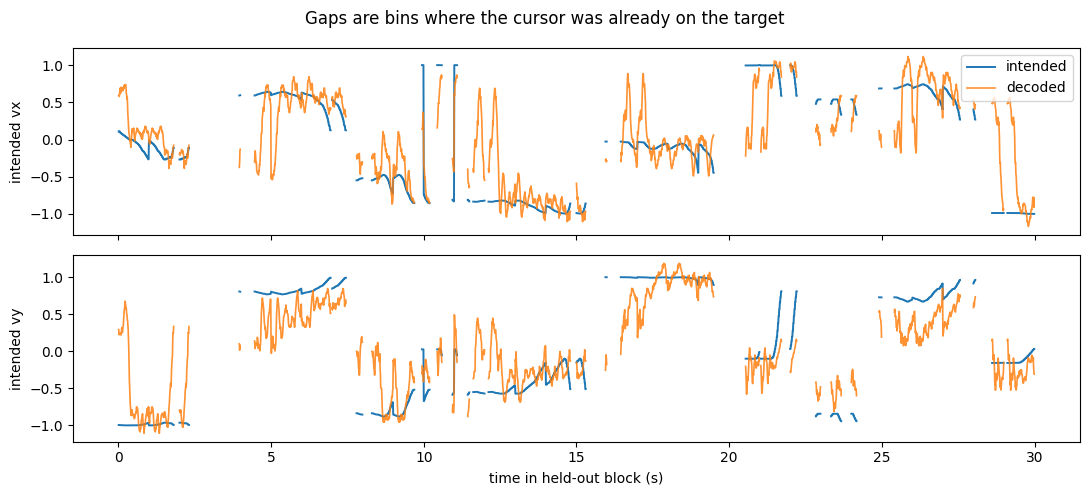

In [10]:
# A contiguous stretch of one held-out block, windows are time ordered.
span = 30
with torch.no_grad():
    traced = model(x_val[:span]).permute(1, 0, 2).reshape(2, -1).numpy()
truth = y_val[:span].permute(1, 0, 2).reshape(2, -1).numpy()
keep = m_val[:span].squeeze(1).reshape(-1).bool().numpy()
time = np.arange(truth.shape[1]) / FS

figure, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for axis, (ax, label) in enumerate(zip(axes, ("intended vx", "intended vy"))):
    ax.plot(time, np.where(keep, truth[axis], np.nan), label="intended", lw=1.4)
    ax.plot(
        time,
        np.where(keep, traced[axis], np.nan),
        label="decoded",
        lw=1.2,
        alpha=0.85,
    )
    ax.set_ylabel(label)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time in held-out block (s)")
figure.suptitle("Gaps are bins where the cursor was already on the target")
plt.tight_layout()
plt.show()

## Takeaways

On two fully held-out day-468 grid blocks, the small temporal-convolutional decoder tracks T15's intended cursor direction at corr ~0.88 and R2 ~0.78 per axis, ahead of the deployed online decoder's own recorded output scored against the same target (corr ~0.79, R2 ~0.59). The point is not that this model is better than the clinical system (it trains and tests offline on curated windows), but that intended velocity is a real decoding target the neural features carry, unlike the online decoder output, which is a linear image of those same features.

This is a deliberately small tutorial. Levers left on the table, roughly in order of expected payoff:

- **More data.** Only the nine closed-loop grid blocks are used here. The radial8 calibration blocks (days 39, 202, 468) add far more intended-movement data once filtered to closed-loop bins with `CursorAssistSeries`, and shorter strides multiply windows cheaply since the extractor is cached.
- **Cross-session generalization.** Training and testing both sit inside day 468. Spanning days 39 to 468 exposes the real BCI problem, neural drift across months, and needs the per-session intention rule (day 39 used position-error speed scaling, not the unit-vector rule).
- **Model and target.** Wider temporal context, recurrent or state-space decoders, and predicting a signed speed rather than a pure unit vector would all help. When validation metrics plateau as capacity grows, the ceiling is the raw binned features and cross-block drift, not the decoder.
